# Distributional Incidence — Who Pays Federal Taxes, Who Gets Transfers, and Who Would Get a Child Transfer

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** CBO *The Distribution of Household Income, 2023* and Census CPS ASEC 2024 (income year 2023)

This notebook uses **real data only**. There is no synthetic generator and no fallback. The tax and transfer incidence is read from a
workbook CBO published; the incidence of a stylised transfer is computed from CPS ASEC weighted cells (no person-level row is read,
printed or stored). The two sources define income differently, and the notebook reconciles them in the open instead of rescaling either.

The analysis was fixed in a written plan (`pap/E03_plan.md`) and two amendments, each committed on its own before the number it
concerns was computed. The notebook is bound to the plan by its SHA-256 and prints the digests of the amendments; it says where it departs from them.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Read** a distributional table (average income, transfers and taxes by income quintile) and turn averages into shares of a total.
2. **Rank** people by household income adjusted for household size, and place a boundary inside a bin when income is known only to its bin.
3. **Compute** the incidence of a stylised transfer by income quintile, race and ethnicity, and the age of the household's reference person.
4. **Report** a survey share with the interval a simple random sample would give, and say why that interval is only a lower bound.
5. **Bound** a share by the weight a small-cell rule withheld, and say when a difference survives that bound.
6. **Reconcile** two income concepts side by side without pretending they agree.

## Prerequisites

**Knowledge.** Weighted shares; quantiles of a weighted distribution; the difference between an average and a total.

**Setup.** A free Census API key from <https://api.census.gov/data/key_signup.html>, supplied by you as the environment variable
`CENSUS_API_KEY`, or as a line `CENSUS_API_KEY=...` in a file whose path you set in `KRL_SECRETS_PATH`. The key is read at runtime and is
never printed or written into this notebook's output. The CPS retrieval is one request and takes a minute or so. The CBO workbook is
committed in the repository (`data/cbo/`) and needs no key.

**Packages.** `pandas`, `numpy`, `matplotlib`, `openpyxl`, and the local `krl_tutorials_data` package (`methods.incidence`).

**Prior notebooks.** E01 for how a cost is built from a government file; none is required.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| `62761-supp-data.xlsx`, sheets 1, 2, 3, 10, 11 and 12 | Congressional Budget Office, *The Distribution of Household Income, 2023* (publication 62761), committed under `data/cbo/` with its digest and the way it was obtained in `SOURCES.md` | average income, means-tested transfers and federal taxes by quintile; people and children by quintile; quintile boundaries |
| `HTOTVAL`, `H_NUMPER`, `A_AGE`, `PRDTRACE`, `PEHSPNON`, `A_EXPRRP`, `MARSUPWT` | Census Bureau, Current Population Survey Annual Social and Economic Supplement 2024 (income year 2023), through the API, as weighted cells only | the stylised transfer's incidence |

Each retrieval is recorded in `provenance/`, bound to the plan's SHA-256.

> **Two income concepts.** CBO ranks people by *income before transfers and taxes* (market income plus social insurance benefits, including
> employers' health contributions and taxes borne by labour), adjusted for household size by the square root of the number of people. The
> CPS ranks here by *household money income* (cash, including cash transfers and Social Security, before taxes), adjusted the same way. They
> are not the same quantity and the quintiles are not the same people. The reconciliation section lines them up.

## Design

**Estimands, all descriptive, all for income year 2023.**

1. *CBO incidence.* For each income quintile: average market income, social insurance benefits, means-tested transfers, federal taxes and income
   after transfers and taxes, and each quintile's share of the totals, as CBO published them. This is an accounting of who pays and who receives, not an estimate of what a change would do.
2. *Incidence of a stylised transfer.* A fixed amount per child, paid to the child's household. Its cost is shared across quintiles of people
   ranked by household income adjusted for size, across race and ethnicity groups, and across the age of the household's reference person.
   The amount and the age limit are set in the configuration cell. It is for illustration; it is not a proposal, and no take-up or behavioural response is modelled.
3. *Reconciliation.* How far the CPS ranking sits from CBO's.

**Rules fixed before the data.** A CPS difference is called "suggested by the sample" only when the sampling lower bound excludes zero *and* the
difference keeps its sign across the bound set by the weight the small-cell rule withheld; otherwise it is "not distinguishable from zero at the precision of this data".

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.connectors import BulkFileSource, frame_from_bulk_file
from krl_tutorials_data.methods import incidence
from krl_tutorials_data.sources import fetch_cps_asec

NB_DIR = REPO_ROOT / "projects" / "10-economic-evaluation" / "E03_distributional_incidence"
PLAN = NB_DIR / "pap" / "E03_plan.md"
AMEND = [NB_DIR / "pap" / "E03_plan_amendment_1.md", NB_DIR / "pap" / "E03_plan_amendment_2.md"]
PLAN_SHA256 = hashlib.sha256(PLAN.read_bytes()).hexdigest()
CBO_FILE = REPO_ROOT / "data" / "cbo" / "62761-supp-data.xlsx"
CBO_SHA256 = "e91c2e8e5012628d8e884e5ad4fc86f2f004cad9113708bbc1038d7ab7b4acbd"

CPS_YEAR = 2024                 # income year 2023
YEAR = 2023
BIN_WIDTH, INCOME_FLOOR, INCOME_CAP = 2500.0, 0.0, 150_000.0   # amendment 1
MIN_CELL_RECORDS = 10                                           # amendment 1
WITHHELD_BOUND = 0.02           # amendment 2 (amendment 1 had 0.01)
BOUNDARY_BIN_MAX = 0.05         # amendment 1
CHILD_AGE, TRANSFER_PER_CHILD = 18, 1000.0
QUINTILES = ["Lowest quintile", "Second quintile", "Middle quintile", "Fourth quintile", "Highest quintile"]
ADDED = "not pre-specified (added after review, 2026-10-27)"

print(f"plan SHA-256         : {PLAN_SHA256}")
for a in AMEND:
    print(f"{a.name:22s}: {hashlib.sha256(a.read_bytes()).hexdigest()}")
print(f"CBO workbook SHA-256 : {CBO_SHA256}")
print(f"bins                 : ${BIN_WIDTH:,.0f} wide, one bin at or above ${INCOME_CAP:,.0f}, one below ${INCOME_FLOOR:,.0f}; cells under {MIN_CELL_RECORDS} records are withheld")
print(f"stop rules           : withheld weight above {WITHHELD_BOUND:.0%} of the population; a boundary bin holding {BOUNDARY_BIN_MAX:.0%} or more")
print(f"stylised transfer    : ${TRANSFER_PER_CHILD:,.0f} per person under {CHILD_AGE}, paid to the household")

plan SHA-256         : 74d2a906ac0b5107064cc2f0aa17ed43a67701738d166997d7f6144b33fff15a
E03_plan_amendment_1.md: 0a22788b520d3ba5d550de8fc066f4095d8758e09ca75830bcc6585162cf8f8d
E03_plan_amendment_2.md: c0847b6d350e18fbdc98eced46fc032c3f919a77e9717acfbb7f57baf47fbd32
CBO workbook SHA-256 : e91c2e8e5012628d8e884e5ad4fc86f2f004cad9113708bbc1038d7ab7b4acbd
bins                 : $2,500 wide, one bin at or above $150,000, one below $0; cells under 10 records are withheld
stop rules           : withheld weight above 2% of the population; a boundary bin holding 5% or more
stylised transfer    : $1,000 per person under 18, paid to the household


## Part 1 · What CBO publishes

The workbook is committed and read through `connectors`, which fails closed if its bytes differ from the recorded digest. Each table's title and
header row are located by their text, not by position, so a change in layout stops the notebook instead of misaligning it.

In [2]:
"""Read the CBO workbook's tables for 2023; the file is pinned by its digest."""
source = BulkFileSource(
    path=CBO_FILE, publisher="Congressional Budget Office",
    dataset="The Distribution of Household Income, 2023 - supplemental data",
    vintage="September 2026 report (publication 62761)", retrieved_on=date(2026, 10, 27),
    sha256=CBO_SHA256, terms_url="https://www.cbo.gov/about/website-policies",
    notes=("Downloaded by the owner in a browser; the publisher's bot protection refuses scripted clients. See data/cbo/SOURCES.md.",),
)
SHEETS = {"demographics": "1. Demographics", "minimums": "2. Income Group Mins", "average": "3. Avg HH Income",
          "share_income": "10. Household Income Shares", "share_transfers": "11. Means-Tested Trans Shares",
          "share_taxes": "12. Federal Taxes Shares"}


def read_table(path: Path, sheet: str) -> pd.DataFrame:
    """One CBO table as a frame: header row found by its first cell, all years kept."""
    raw = pd.read_excel(path, sheet_name=sheet, header=None)
    first = raw[0].astype(str)
    hdr = first[first.isin(["Income group", "Household size"])].index
    if len(hdr) != 1:
        raise SystemExit(f"{sheet}: expected one header row, found {len(hdr)}")
    names = [str(v).replace("\n", " ").strip() for v in raw.iloc[hdr[0]]]
    table = raw.iloc[hdr[0] + 1:].copy()
    table.columns = names
    table = table[pd.to_numeric(table["Year"], errors="coerce").notna()].copy()
    table["Year"] = table["Year"].astype(int)
    return table.reset_index(drop=True)


cbo = {}
for key, sheet in SHEETS.items():
    frame, prov = frame_from_bulk_file(source, lambda p, s=sheet: read_table(p, s))
    prov.with_pap(PLAN).write(NB_DIR / "provenance" / f"e03_cbo_{key}.json")
    cbo[key] = frame[frame["Year"] == YEAR].reset_index(drop=True)
    print(f"{sheet:32s}: {len(frame):4d} rows, {len(cbo[key])} for {YEAR}; digest {prov.content_sha256[:12]}")

1. Demographics                 :  450 rows, 10 for 2023; digest d74a8e5fa7c5
2. Income Group Mins            :  180 rows, 4 for 2023; digest d74a8e5fa7c5
3. Avg HH Income                :  450 rows, 10 for 2023; digest d74a8e5fa7c5
10. Household Income Shares     :  450 rows, 10 for 2023; digest d74a8e5fa7c5
11. Means-Tested Trans Shares   :  450 rows, 10 for 2023; digest d74a8e5fa7c5


12. Federal Taxes Shares        :  450 rows, 10 for 2023; digest d74a8e5fa7c5


### Average income, transfers and taxes by quintile

CBO's averages are *per household*. Quintiles hold different numbers of households (and of people), so a quintile's share of a total is its
average times its households, divided by the same product summed over quintiles. The notebook recomputes the shares that way and checks them against
the shares CBO printed.

In [3]:
avg = cbo["average"].set_index("Income group")
dem = cbo["demographics"].set_index("Income group")
cols = ["Market income", "Social insurance benefits", "Income before transfers and taxes", "Means-tested transfers", "Federal taxes", "Income after transfers and taxes"]
show = avg.loc[QUINTILES + ["All quintiles"], cols].astype(float)
show.insert(0, "Households (millions)", dem.loc[QUINTILES + ["All quintiles"], "Number of households"].astype(float))
show.insert(1, "People (millions)", dem.loc[QUINTILES + ["All quintiles"], "Number of people"].astype(float))
print(f"CBO {YEAR}: average per household, 2023 dollars")
print(show.round(0).to_string(float_format=lambda v: f"{v:,.0f}" if abs(v) > 1000 else f"{v:,.1f}"))
for c in ("Means-tested transfers", "Federal taxes"):
    low, high = show.loc["Lowest quintile", c], show.loc["Highest quintile", c]
    print(f"{c}: lowest quintile ${low:,.0f}, highest quintile ${high:,.0f} per household")
direction_transfers = float(show.loc["Lowest quintile", "Means-tested transfers"]) > float(show.loc["Highest quintile", "Means-tested transfers"])
direction_taxes = float(show.loc["Highest quintile", "Federal taxes"]) > float(show.loc["Lowest quintile", "Federal taxes"])
print(f"FALSIFICATION: direction_cbo statistic={int(direction_transfers and direction_taxes)} transfers fall and taxes rise from lowest to highest quintile verdict={'PASS' if direction_transfers and direction_taxes else 'FAIL'}")

CBO 2023: average per household, 2023 dollars
                  Households (millions)  People (millions)  Market income  Social insurance benefits  Income before transfers and taxes  Means-tested transfers  Federal taxes  Income after transfers and taxes
Income group                                                                                                                                                                                                    
Lowest quintile                    26.0               64.0         20,900                      7,600                             28,500                  20,100          100.0                            48,400
Second quintile                    27.0               65.0         47,200                     15,900                             63,100                   9,900          6,000                            67,000
Middle quintile                    27.0               65.0         79,300                     19,300                  

In [4]:
"""Shares of totals: recomputed (average x households) against the shares CBO printed."""
hh = dem.loc[QUINTILES, "Number of households"].astype(float)
pairs = {"Income before transfers and taxes": ("share_income", "Income before transfers and taxes"),
         "Means-tested transfers": ("share_transfers", "Means-tested transfers"),
         "Federal taxes": ("share_taxes", "Federal taxes")}
rows, worst = [], 0.0
for name, (key, col) in pairs.items():
    published = cbo[key].set_index("Income group").loc[QUINTILES, col].astype(float)
    total = (avg.loc[QUINTILES, name].astype(float) * hh)
    recomputed = 100 * total / total.sum()
    worst = max(worst, float((recomputed - published).abs().max()))
    for q in QUINTILES:
        rows.append({"measure": name, "quintile": q, "published %": published[q], "recomputed %": recomputed[q]})
    print(f"{name}: lowest quintile {published['Lowest quintile']:.1f}% (published) {recomputed['Lowest quintile']:.1f}% (recomputed); highest {published['Highest quintile']:.1f}% and {recomputed['Highest quintile']:.1f}%")
cbo_shares = pd.DataFrame(rows)
print(f"largest gap between published and recomputed shares: {worst:.2f} percentage points")
print(f"FALSIFICATION: cbo_shares_recomputed statistic={worst:.3f} percentage points; CBO rounds dollars to the nearest hundred and shares to a tenth, so a gap above 0.5 is a failure verdict={'PASS' if worst <= 0.5 else 'FAIL'}")
note_sum = float(cbo['share_transfers'].set_index('Income group').loc[QUINTILES, 'Means-tested transfers'].astype(float).sum())
print(f"published shares of means-tested transfers add to {note_sum:.1f}%; negative-income households sit outside the lowest quintile but inside the totals, so the sum can fall short of 100")

Income before transfers and taxes: lowest quintile 3.8% (published) 3.8% (recomputed); highest 54.7% and 54.3%
Means-tested transfers: lowest quintile 48.9% (published) 49.2% (recomputed); highest 4.2% and 4.2%
Federal taxes: lowest quintile 0.1% (published) 0.1% (recomputed); highest 69.8% and 69.9%
largest gap between published and recomputed shares: 0.42 percentage points
FALSIFICATION: cbo_shares_recomputed statistic=0.425 percentage points; CBO rounds dollars to the nearest hundred and shares to a tenth, so a gap above 0.5 is a failure verdict=PASS
published shares of means-tested transfers add to 99.2%; negative-income households sit outside the lowest quintile but inside the totals, so the sum can fall short of 100


## Part 2 · A stylised transfer in the CPS

The CPS ASEC is retrieved as weighted cells of (household income adjusted for size, in bins) × race and ethnicity × the age group of the household's
reference person × a child indicator. A cell under the floor is withheld and counted. The API serves no replicate weights, so sampling error is
not computed by the client; the notebook uses Kish's effective sample size and says what that leaves out.

In [5]:
"""One CPS ASEC request, cells only, bound to the plan."""
cells, cps_prov = fetch_cps_asec(year=CPS_YEAR, bin_width=BIN_WIDTH, income_floor=INCOME_FLOOR,
                                 income_cap=INCOME_CAP, child_age=CHILD_AGE, min_cell_records=MIN_CELL_RECORDS)
cps_prov.with_pap(PLAN).write(NB_DIR / "provenance" / f"e03_cps_asec_{CPS_YEAR}.json")
kept_w = float(cells["weighted_n"].sum())
withheld_w = float(cells.attrs["suppressed_weighted_n"])
withheld_share = withheld_w / (kept_w + withheld_w)
print(f"records read          : {cells.attrs['records_read']:,}")
print(f"cells kept            : {len(cells):,} ({int(cells['n_records'].sum()):,} records)")
print(f"cells withheld        : {cells.attrs['suppressed_cells']:,} ({cells.attrs['suppressed_records']:,} records, {withheld_w:,.0f} weighted people)")
print(f"withheld share        : {withheld_share:.2%} of the weighted population (stop rule {WITHHELD_BOUND:.0%})")
print(f"weighted population   : {kept_w:,.0f} kept; {kept_w + withheld_w:,.0f} with the withheld cells")
print(f"weighted children     : {float(cells.loc[cells['child'] == 1, 'weighted_n'].sum()):,.0f} kept")
print(f"payload digest        : {cps_prov.content_sha256[:16]}")
if withheld_share > WITHHELD_BOUND:
    raise SystemExit(f"withheld share {withheld_share:.2%} exceeds the {WITHHELD_BOUND:.0%} stop rule; ask the owner")

records read          : 144,265
cells kept            : 1,242 (142,356 records)
cells withheld        : 444 (1,909 records, 4,531,099 weighted people)
withheld share        : 1.36% of the weighted population (stop rule 2%)
weighted population   : 327,851,386 kept; 332,382,485 with the withheld cells
weighted children     : 69,513,841 kept
payload digest        : b2cd088ca3b5ed24


### Quintile boundaries inside bins

People are ranked by household income divided by the square root of household size. Income is known only to its bin, so each bin that holds a
quintile boundary is split by assuming people are spread evenly across it. The bin's share of the population says how much that assumption governs.

In [6]:
bins = (cells.groupby("income_bin")["weighted_n"].sum().rename("weight").reset_index().rename(columns={"income_bin": "bin"}))
frac, edges = incidence.bin_group_fractions(bins, width=BIN_WIDTH, groups=5)
edges = edges.assign(quintile_above=QUINTILES[1:])
print("CPS quintile boundaries (household income adjusted for size, dollars), and the bin that holds each")
print(edges.rename(columns={"boundary": "boundary $", "bin_share": "share of population in the bin"}).to_string(
    float_format=lambda v: f"{v:,.0f}" if v > 1 else f"{v:.3%}"))
worst_bin = float(edges["bin_share"].max())
inside = bool(((edges["boundary"] > INCOME_FLOOR) & (edges["boundary"] < INCOME_CAP)).all())
print(f"FALSIFICATION: boundary_bin_share statistic={worst_bin:.4f} largest share of the population in a boundary bin; the plan bound is {BOUNDARY_BIN_MAX:.0%} and every boundary lies between the tail bins verdict={'PASS' if worst_bin < BOUNDARY_BIN_MAX and inside else 'FAIL'}")
if worst_bin >= BOUNDARY_BIN_MAX or not inside:
    raise SystemExit("boundary bin rule failed; ask the owner")

keyed = cells.join(frac, on="income_bin")
for g, name in enumerate(QUINTILES):
    keyed[f"w_{g}"] = keyed["weighted_n"] * keyed[g]
    keyed[f"w2_{g}"] = keyed["sum_w2"] * keyed[g]
people_q = pd.Series({name: float(keyed[f"w_{g}"].sum()) for g, name in enumerate(QUINTILES)})
child_q = pd.Series({name: float(keyed.loc[keyed["child"] == 1, f"w_{g}"].sum()) for g, name in enumerate(QUINTILES)})
people_w2 = pd.Series({name: float(keyed[f"w2_{g}"].sum()) for g, name in enumerate(QUINTILES)})
print(f"people per CPS quintile (millions): " + ", ".join(f"{v / 1e6:.1f}" for v in people_q))

CPS quintile boundaries (household income adjusted for size, dollars), and the bin that holds each
     boundary $  share of population in the bin    quintile_above
cut                                                              
1        26,212                          2.698%   Second quintile
2        45,633                          2.528%   Middle quintile
3        68,603                          1.747%   Fourth quintile
4       106,491                          0.963%  Highest quintile
FALSIFICATION: boundary_bin_share statistic=0.0270 largest share of the population in a boundary bin; the plan bound is 5% and every boundary lies between the tail bins verdict=PASS
people per CPS quintile (millions): 65.6, 65.6, 65.6, 65.6, 65.6


### The transfer's incidence

The transfer is a fixed amount per child, so a group's share of its cost is the group's share of children. The interval beside each share has
two separate parts, and they answer different questions:

- the **sampling** interval is what a simple random sample of this effective size would give; it is a **lower bound** on the true interval,
  because the CPS design clusters and stratifies and the API serves no replicate weights;
- the **withheld-weight bound** is the range the share could take if the people in withheld cells were all in this group or all outside it; it assumes nothing about where they are.

In [7]:
"""Incidence by quintile, race and ethnicity, and reference-person age group, with both intervals."""
Z = incidence.Z95
child_cells = cells[cells["child"] == 1]
T_child, T_child_w2 = float(child_cells["weighted_n"].sum()), float(child_cells["sum_w2"].sum())
W = withheld_w


def row(label, group_w, total_w, total_w2, people_w=None, people_w2=None):
    """One group: share of the transfer with both intervals, and the transfer per person."""
    r = incidence.share_with_lower_bound(group_w=group_w, total_w=total_w, total_w2=total_w2)
    lo = r.share * total_w / (total_w + W)
    hi = (r.share * total_w + W) / (total_w + W)
    out = {"group": label, "share %": 100 * r.share, "sampling low": 100 * r.low, "sampling high": 100 * r.high,
           "withheld low": 100 * lo, "withheld high": 100 * hi, "children (millions)": group_w / 1e6}
    if people_w is not None:
        k = incidence.share_with_lower_bound(group_w=group_w, total_w=people_w, total_w2=people_w2)
        out["$ per person"] = TRANSFER_PER_CHILD * k.share
        out["$ low"], out["$ high"] = TRANSFER_PER_CHILD * k.low, TRANSFER_PER_CHILD * k.high
        out["people (millions)"] = people_w / 1e6
    return out


quint = pd.DataFrame([row(q, child_q[q], T_child, T_child_w2, people_q[q], people_w2[q]) for q in QUINTILES])
print("Share of the stylised transfer by quintile of people (CPS, income adjusted for household size)")
print(quint.round(2).to_string(index=False))
print(f"FALSIFICATION: shares_sum_quintile statistic={abs(quint['share %'].sum() - 100):.6f} percentage points verdict={'PASS' if abs(quint['share %'].sum() - 100) < 0.001 else 'FAIL'}")

race_order = ["Hispanic", "White alone", "Black alone", "Asian alone", "Other non-Hispanic"]
race_rows = []
for r_ in race_order:
    c, a = child_cells[child_cells["race"] == r_], cells[cells["race"] == r_]
    race_rows.append(row(r_, float(c["weighted_n"].sum()), T_child, T_child_w2, float(a["weighted_n"].sum()), float(a["sum_w2"].sum())))
race = pd.DataFrame(race_rows)
print("\nShare of the stylised transfer by race and ethnicity of the child")
print(race.round(2).to_string(index=False))
print(f"FALSIFICATION: shares_sum_race statistic={abs(race['share %'].sum() - 100):.6f} percentage points verdict={'PASS' if abs(race['share %'].sum() - 100) < 0.001 else 'FAIL'}")

age_order = ["Under 35", "35-64", "65 and over"]
age_rows = []
for a_ in age_order:
    c, a = child_cells[child_cells["ref_age"] == a_], cells[cells["ref_age"] == a_]
    age_rows.append(row(a_, float(c["weighted_n"].sum()), T_child, T_child_w2, float(a["weighted_n"].sum()), float(a["sum_w2"].sum())))
ages = pd.DataFrame(age_rows)
print("\nShare of the stylised transfer by age of the household's reference person")
print(ages.round(2).to_string(index=False))
print(f"FALSIFICATION: shares_sum_age statistic={abs(ages['share %'].sum() - 100):.6f} percentage points verdict={'PASS' if abs(ages['share %'].sum() - 100) < 0.001 else 'FAIL'}")

Share of the stylised transfer by quintile of people (CPS, income adjusted for household size)
           group  share %  sampling low  sampling high  withheld low  withheld high  children (millions)  $ per person  $ low  $ high  people (millions)
 Lowest quintile    26.52         25.97          27.07         24.90          31.02                18.44        281.15 275.02  287.27              65.57
 Second quintile    22.17         21.64          22.69         20.81          26.93                15.41        234.99 229.28  240.70              65.57
 Middle quintile    19.72         19.22          20.22         18.51          24.63                13.71        209.07 203.58  214.56              65.57
 Fourth quintile    16.59         16.12          17.06         15.57          21.69                11.53        175.88 170.69  181.07              65.57
Highest quintile    15.00         14.55          15.45         14.08          20.20                10.43        159.05 153.99  164.11       

### The pre-specified direction, and the one pre-specified contrast

The plan said before the data that the lowest quintile's share of the transfer would exceed one fifth and the highest quintile's would fall below it.
The contrast between those two quintiles is the one comparison the plan names; the notebook applies the rule from the design section to it.

In [8]:
lo_q, hi_q = quint.iloc[0], quint.iloc[-1]
print(f"lowest quintile share  : {lo_q['share %']:.1f}% (sampling {lo_q['sampling low']:.1f} to {lo_q['sampling high']:.1f}; withheld bound {lo_q['withheld low']:.1f} to {lo_q['withheld high']:.1f})")
print(f"highest quintile share : {hi_q['share %']:.1f}% (sampling {hi_q['sampling low']:.1f} to {hi_q['sampling high']:.1f}; withheld bound {hi_q['withheld low']:.1f} to {hi_q['withheld high']:.1f})")
direction = (lo_q["share %"] > 20.0) and (hi_q["share %"] < 20.0)
print(f"FALSIFICATION: direction_cps statistic={lo_q['share %'] - hi_q['share %']:.2f} percentage points, lowest minus highest quintile; expected: lowest above 20% and highest below 20% verdict={'PASS' if direction else 'FAIL'}")

p1, p2 = lo_q["share %"] / 100, hi_q["share %"] / 100
n_eff = incidence.kish_effective_n(sum_w=T_child, sum_w2=T_child_w2)
se_diff = float(np.sqrt((p1 + p2 - (p1 - p2) ** 2) / n_eff))          # shares of one multinomial total
diff = p1 - p2
s_low, s_high = diff - Z * se_diff, diff + Z * se_diff
b_low, b_high = (lo_q["withheld low"] - hi_q["withheld high"]) / 100, (lo_q["withheld high"] - hi_q["withheld low"]) / 100
print(f"difference in shares (lowest minus highest): {100 * diff:+.1f} percentage points")
print(f"  sampling lower-bound interval : {100 * s_low:+.1f} to {100 * s_high:+.1f}")
print(f"  withheld-weight bound         : {100 * b_low:+.1f} to {100 * b_high:+.1f}")
suggested = (s_low > 0 or s_high < 0) and (b_low > 0 or b_high < 0)
print("reading: " + ("suggested by the sample (the lower-bound interval excludes zero and the sign survives the withheld-weight bound)" if suggested
      else "not distinguishable from zero at the precision of this data; the interval is stated in percentage points above"))

lowest quintile share  : 26.5% (sampling 26.0 to 27.1; withheld bound 24.9 to 31.0)
highest quintile share : 15.0% (sampling 14.6 to 15.5; withheld bound 14.1 to 20.2)
FALSIFICATION: direction_cps statistic=11.52 percentage points, lowest minus highest quintile; expected: lowest above 20% and highest below 20% verdict=PASS
difference in shares (lowest minus highest): +11.5 percentage points
  sampling lower-bound interval : +10.7 to +12.3
  withheld-weight bound         : +4.7 to +16.9
reading: suggested by the sample (the lower-bound interval excludes zero and the sign survives the withheld-weight bound)


## Part 3 · Reconciling the two sources

CBO's workbook gives, for 2023, each quintile's number of people and children and the lowest income that belongs to each quintile for a household of one.
The CPS side has the same quantities from its own income measure. They are placed side by side, as printed, and the ratio is described and not corrected.

In [9]:
mins = cbo["minimums"].copy()
mins["Household size"] = mins["Household size"].astype(str)
one = mins[mins["Household size"].str.strip().isin(["1", "1.0"])]
cbo_min = [float(one.iloc[0][q]) for q in QUINTILES[1:]] if len(one) else None
if cbo_min is None:
    raise SystemExit("CBO minimums for a household of one were not found")
recon_b = pd.DataFrame({"quintile starts at": QUINTILES[1:], "CBO $ (income before transfers and taxes)": cbo_min,
                        "CPS $ (household money income)": edges["boundary"].to_numpy()})
recon_b["CPS / CBO"] = recon_b.iloc[:, 2] / recon_b.iloc[:, 1]
print("Quintile boundaries for a one-person household (income divided by the square root of household size)")
print(recon_b.to_string(index=False, float_format=lambda v: f"{v:,.0f}" if v > 10 else f"{v:.2f}"))

cbo_people = dem.loc[QUINTILES, "Number of people"].astype(float).to_numpy()
cbo_kids = dem.loc[QUINTILES, "Number of children"].astype(float).to_numpy()
recon_n = pd.DataFrame({"quintile": QUINTILES, "CBO people (M)": cbo_people, "CPS people (M)": people_q.to_numpy() / 1e6,
                        "CBO children (M)": cbo_kids, "CPS children (M)": child_q.to_numpy() / 1e6})
recon_n["CPS / CBO children"] = recon_n["CPS children (M)"] / recon_n["CBO children (M)"]
print("\nPeople and children by quintile, millions (the CPS figures exclude the withheld cells)")
print(recon_n.to_string(index=False, float_format=lambda v: f"{v:.1f}" if v > 3 else f"{v:.2f}"))
tot_cbo = float(dem.loc["All quintiles", "Number of people"]); tot_cps = kept_w / 1e6
print(f"all people: CBO {tot_cbo:.1f} million; CPS {tot_cps:.1f} million kept, {(kept_w + withheld_w) / 1e6:.1f} million with the withheld cells; ratio {tot_cps / tot_cbo:.3f}")
print(f"children share in the lowest quintile: CBO {100 * cbo_kids[0] / cbo_kids.sum():.1f}%; CPS {quint.iloc[0]['share %']:.1f}%")

Quintile boundaries for a one-person household (income divided by the square root of household size)
quintile starts at  CBO $ (income before transfers and taxes)  CPS $ (household money income)  CPS / CBO
   Second quintile                                     31,800                          26,212       0.82
   Middle quintile                                     53,700                          45,633       0.85
   Fourth quintile                                     79,800                          68,603       0.86
  Highest quintile                                    122,200                         106,491       0.87

People and children by quintile, millions (the CPS figures exclude the withheld cells)
        quintile  CBO people (M)  CPS people (M)  CBO children (M)  CPS children (M)  CPS / CBO children
 Lowest quintile            63.8            65.6              20.7              18.4                0.89
 Second quintile            64.9            65.6              14.9          

### What the table shows

The CPS ranks on a measure that already includes cash transfers and Social Security and excludes employers' contributions and taxes borne by labour; CBO ranks before
all transfers. Households that cash transfers lift out of the bottom of the CBO ranking sit higher in the CPS ranking, so the CPS boundaries and quintile populations
differ from CBO's in a direction the sign of the ratios above shows. This is a difference of definition, not a measurement error in either source, and nothing here
rescales one onto the other.

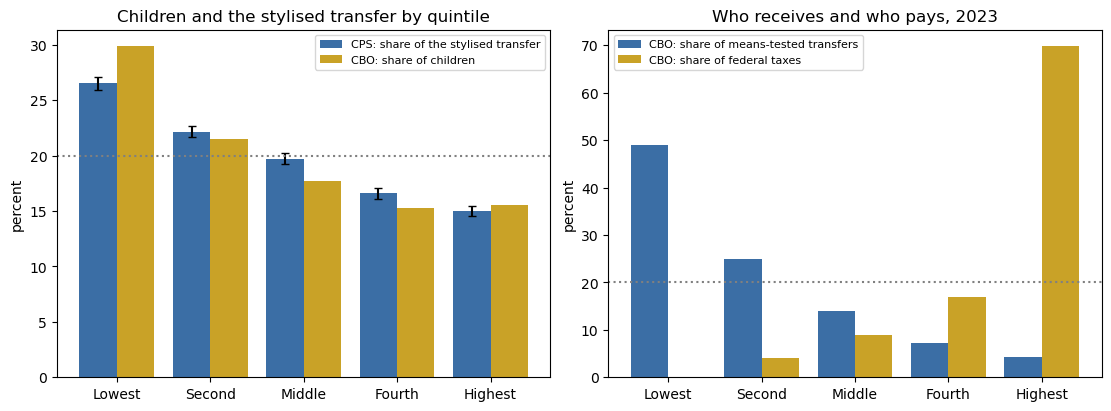

Left: bars are shares of the stylised transfer (CPS, with the sampling lower-bound interval) next to CBO's share of children. Right: CBO's published shares. Dotted line: one fifth.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
x = np.arange(5)
axes[0].bar(x - 0.2, quint["share %"], 0.4, yerr=[quint["share %"] - quint["sampling low"], quint["sampling high"] - quint["share %"]], label="CPS: share of the stylised transfer", color="#3b6ea5", capsize=3)
axes[0].bar(x + 0.2, 100 * cbo_kids / cbo_kids.sum(), 0.4, label="CBO: share of children", color="#c9a227")
axes[0].axhline(20, color="grey", linestyle=":")
axes[0].set_xticks(x, ["Lowest", "Second", "Middle", "Fourth", "Highest"])
axes[0].set_ylabel("percent"); axes[0].set_title("Children and the stylised transfer by quintile"); axes[0].legend(fontsize=8)
tr = cbo["share_transfers"].set_index("Income group").loc[QUINTILES, "Means-tested transfers"].astype(float)
tx = cbo["share_taxes"].set_index("Income group").loc[QUINTILES, "Federal taxes"].astype(float)
axes[1].bar(x - 0.2, tr, 0.4, label="CBO: share of means-tested transfers", color="#3b6ea5")
axes[1].bar(x + 0.2, tx, 0.4, label="CBO: share of federal taxes", color="#c9a227")
axes[1].axhline(20, color="grey", linestyle=":")
axes[1].set_xticks(x, ["Lowest", "Second", "Middle", "Fourth", "Highest"])
axes[1].set_ylabel("percent"); axes[1].set_title("Who receives and who pays, 2023"); axes[1].legend(fontsize=8)
plt.show()
print("Left: bars are shares of the stylised transfer (CPS, with the sampling lower-bound interval) next to CBO's share of children. Right: CBO's published shares. Dotted line: one fifth.")

## Limitations

- **The two income concepts differ and are not harmonised.** CBO ranks by income before transfers and taxes, including employers' contributions and taxes borne by labour; the CPS
  ranks by household money income, which includes cash transfers and Social Security and excludes those items. The reconciliation tables show the effect on boundaries and populations.
  The plan expected to compare mean incomes by quintile; the CBO workbook publishes no size-adjusted mean, so the notebook compares the quintile boundaries for a household of one and
  the numbers of people and children, which are the quantities both sides have in the same units. That is a departure from the plan's section on reconciliation, forced by what the file contains.
- **The CPS sampling intervals are lower bounds.** The API serves no replicate weights, so the interval treats the sample as a simple random sample with Kish's effective size and ignores
  clustering and stratification, which can only widen the true interval. A difference "suggested by the sample" is therefore suggested at a precision the data may not have.
- **Withheld cells.** The client withholds cells under the record floor. The withheld share is printed and is above the 1% bound in amendment 1; amendment 2, after the stop rule fired, moved the
  bound to 2% on the owner's ruling and required every share to be bounded by the withheld weight. The bound assumes nothing about where those people are; withheld cells are thin
  cells, so they sit in the tails of income and in small race and age groups, where the shares are least certain.
- **Even spread inside a bin.** Quintile boundaries sit inside $2,500 bins and people are taken to be spread evenly across the bin that holds a boundary; the boundary-bin share is printed.
- **Shares from averages.** The plan said to divide each quintile's value by the sum across quintiles. CBO's values are averages per household and the quintiles hold different numbers of households,
  so that is not a share of the total; the notebook uses CBO's own published shares and checks them against average times households. This is a departure from the plan's wording.
- **A stylised transfer is not a proposal.** It ignores take-up, phase-outs, taxation and behaviour. It is paid per child to the household; the incidence by reference-person age is the age of the household's reference person, not of the child.
- **Money income is under-reported at both ends** in the CPS, and the top is topcoded; the cap bin holds everyone above its lower edge.
- **Race groups pool small populations.** American Indian and Alaska Native alone, Pacific Islander alone and people of two or more races are combined with a small group of others because the CPS cannot estimate them separately. Hispanic origin takes precedence over race.
- **One income year.** CBO and the CPS are both for income year 2023. Nothing here says how any of it changed over time, though the CBO workbook covers 1979 to 2023.
- **Departures from the plan.** The plan was not edited. Amendment 1 changed the bin width, tails, floor and boundary-bin bound before the data were retrieved. Amendment 2 raised the withheld-weight bound after the stop rule fired.
  The two departures named above (the reconciliation by boundaries and counts, and the shares from published values) are not in either amendment and are stated here instead.

## Key Takeaways

1. A table of averages is not a table of shares: a quintile's share of a total needs its number of households, and the notebook checks CBO's published shares against that product.
2. Ranking people by income is a choice of income concept. Ranking before transfers and taxes, as CBO does, and ranking by money income, as the CPS does here, put different people in the same quintile, and the gap is a finding about definitions, not an error.
3. When income is known only to its bin, a quantile boundary is an interpolation, and the honest report includes how much of the population sits in the bin that holds it.
4. A survey share needs two kinds of caution: a sampling interval that, without replicate weights, is only a lower bound, and a bound set by the weight a disclosure rule withheld. A difference deserves a stronger word only when it survives both.
5. A stylised transfer shows how an instrument's design, here a fixed amount per child, determines who receives it before any behaviour is considered.

## Exercises

1. Replace the fixed amount per child with an amount that falls to zero above a household income threshold you choose. Which quintile's share changes most, and what does the withheld-weight bound say about the change?
2. Rank by `HTOTVAL` less a rough estimate of federal taxes and compare the quintile populations with CBO's again.
3. Compute the share of the transfer going to children in households whose reference person is under 35, and say which of the two intervals matters more for that group.
4. Use CBO's table of income-group minimums for a household of four. How far do the CPS boundaries for four-person households sit from CBO's?

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- Congressional Budget Office, *The Distribution of Household Income, 2023* (publication 62761) and its supplemental data workbook.
- Kish, L. (1965), *Survey Sampling*, Wiley (effective sample size).
- U.S. Census Bureau, *Current Population Survey Annual Social and Economic Supplement* technical documentation, 2024.